# Active GLiNER: Decisions: one answer from a list

The task: pick exactly one answer from a fixed list of options. For example, *"how much is left on my visa card"* gives the intent `balance`.

This notebook follows the recipe from the paper:

```
your unlabelled texts
   │  1. the untrained student ranks them once, least sure first
   ▼
top N texts ──> a random quarter: human labels
           └──> the rest: LLM labels
   │  2. train the student on both (LoRA)
   ▼
a small, fast model you own ──> 3. check it on labelled dev data ──> 4. predict
```

Data: CLINC150: assistant requests, 150 intents plus `oos` (out of scope). The "human" labels here come from the dataset's own annotators, so you
can see the recipe end to end without labelling anything yourself.

You need a GPU (8 GB is enough) and an OpenAI-compatible LLM server. This repository
starts Gemma 4 12B with `scripts/serve_teacher_gemma.sh`; any other local or hosted
endpoint works too.

In [1]:
import json
from pathlib import Path

import torch
from IPython.display import Image, Markdown, display

from active_gliner import byod, data, tasks

TASK = "decision"
DATASET = "clinc150"
TEACHER_URL = "http://127.0.0.1:8020/v1"
TEACHER_MODEL = "gemma-4-12b-qat"
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none")

GPU: NVIDIA GeForce RTX 3090


## 1. Your data

The tool reads JSONL files, one text per line:

+ `texts.jsonl` - unlabelled texts (`text`, and for relations the `entities` list).
+ `dev.jsonl` - a few hundred texts with correct labels, to measure accuracy.

Here we write both from the dataset.

In [2]:
demo = Path("demo-decision")
demo.mkdir(exist_ok=True)
splits = data.load(DATASET)
names = tasks.labels(DATASET, splits)  # label code -> label name


def write(path, records, with_labels):
    rows = [byod.record_to_row(r, names, with_labels) for r in records]
    path.write_text("".join(json.dumps(row, ensure_ascii=False) + "\n" for row in rows))


write(demo / "texts.jsonl", splits["pool"][:5000], with_labels=False)
write(demo / "dev.jsonl", splits["dev"][:300], with_labels=True)
labels = ",".join(names.values())
print(len(names), "labels:", labels[:200], "...")
print(open(demo / "dev.jsonl").readline()[:300])

151 labels: accept reservations,account blocked,alarm,application status,apr,are you a bot,balance,bill balance,bill due,book flight,book hotel,calculator,calendar,calendar update,calories,cancel,cancel reservati ...
{"id": "clinc150:en-US:dev-0", "text": "in spanish, meet me tomorrow is said how", "label": "translate"}



## 2. What the untrained student does

GLiNER2.5 already works for any label names, with no training. This is the score to beat.

In [3]:
task = tasks.for_dataset(DATASET)
dev = byod.read_labelled(demo / "dev.jsonl", TASK)
label_map = byod.parse_labels(labels)
student = byod.load_student(TASK, label_map)
zero_shot_f1 = task.score(dev, task.predict(student, dev, label_map), label_map)["micro"]["f1"]
print(f"Zero-shot dev F1: {100 * zero_shot_f1:.1f}")
del student
torch.cuda.empty_cache()

Zero-shot dev F1: 68.7


## 3. Rank once and split between humans and the LLM

`rank` scores every text with the untrained student, takes the 1,000 it is least sure
about (texts where it finds nothing go last), and puts a random quarter of them in
`for_humans.jsonl`. The rest goes in `for_llm.jsonl`.

From a terminal:

```bash
active-gliner rank --texts demo/texts.jsonl --task decision --labels "..." \
  --n 1000 --human-share 0.25 --out demo/rank
```

In [4]:
ranked = byod.rank(
    demo / "texts.jsonl", TASK, labels, n=1000, human_share=0.25, out_dir=demo / "rank"
)
for_humans = [json.loads(line) for line in (ranked / "for_humans.jsonl").open()]
for_llm = [json.loads(line) for line in (ranked / "for_llm.jsonl").open()]
print(len(for_humans), "texts for humans,", len(for_llm), "for the LLM")
print("example for a human:", for_humans[0]["text"][:200])

250 texts for humans, 750 for the LLM
example for a human: what subjects do you know well


## 4. Human labels

In real use, people label `for_humans.jsonl` by hand, in the same format as `dev.jsonl`.
Here we copy the dataset's own labels for those texts.

In [5]:
by_id = {r.id: r for r in splits["pool"]}
write(demo / "human.jsonl", [by_id[row["id"]] for row in for_humans], with_labels=True)
print(open(demo / "human.jsonl").readline()[:300])

{"id": "clinc150:en-US:train-2196", "text": "what subjects do you know well", "label": "what can i ask you"}



## 5. LLM labels for the rest, then train

`fit` sends every text in `for_llm.jsonl` to the LLM (`select="all"`), checks every
answer (valid JSON, allowed labels, exact text spans), adds the human-labelled texts,
and trains a LoRA adapter. The LLM never sees the human-labelled texts.

```bash
active-gliner fit --texts demo/rank/for_llm.jsonl --select all --human demo/human.jsonl \
  --task decision --labels "..." --dev demo/dev.jsonl \
  --teacher-url http://127.0.0.1:8020/v1 --teacher-model gemma-4-12b-qat --out demo/run
```

For a hosted API, also pass `api_key_env="NAME_OF_THE_KEY_VARIABLE"`.

In [6]:
run = byod.fit(
    texts=ranked / "for_llm.jsonl",
    task=TASK,
    labels=labels,
    teacher_url=TEACHER_URL,
    teacher_model=TEACHER_MODEL,
    select="all",
    human=demo / "human.jsonl",
    dev=demo / "dev.jsonl",
    out_dir=demo / "run",
)
print(run)

demo-decision/run


## 6. Check the result

Every run folder holds plain files: a one-page report, training curves, every LLM label
and every wrong prediction.

In [7]:
metrics = json.loads((run / "metrics.json").read_text())
trained_f1 = metrics["dev"]["micro"]["f1"]
print(f"Dev F1: zero-shot {100 * zero_shot_f1:.1f} -> trained {100 * trained_f1:.1f}")
print("LLM answers:", json.loads((run / "teacher_stats.json").read_text()))

Dev F1: zero-shot 68.7 -> trained 92.7
LLM answers: {'elapsed_s': 0.09048998611979187, 'workers': 8, 'gpu_shared': False, 'requests': 0, 'cache_hits': 750, 'retries': 0, 'duplicate': 0, 'prompt_tokens': 0, 'completion_tokens': 0, 'latency_s_total': 0.0, 'errors_by_kind': {}, 'invalid_records': 0, 'valid_rate': 1.0, 'cost_usd': 0.0}


In [8]:
display(Markdown((run / "report.md").read_text()))

# user: all, N=750, seed=1

Locale: en-US. Labels: custom. LoRA r=32, alpha=64.0, task LR=0.0004019207998187699. Augmentation: False.
Acquisition threshold: 0.5. Evaluation threshold: 0.5.

| Split | Micro F1 | Macro F1 |
| --- | ---: | ---: |
| dev | 0.9267 | 0.0951 |

Best step: 800. Stop reason: max_steps.
Wall time: 328.77 s. Training time: 294.44 s.

| Type | Precision | Recall | F1 | Support |
| --- | ---: | ---: | ---: | ---: |
| accept reservations | 0.0000 | 0.0000 | 0.0000 | 0 |
| account blocked | 0.0000 | 0.0000 | 0.0000 | 0 |
| alarm | 0.0000 | 0.0000 | 0.0000 | 0 |
| application status | 0.0000 | 0.0000 | 0.0000 | 0 |
| apr | 0.0000 | 0.0000 | 0.0000 | 0 |
| are you a bot | 0.0000 | 0.0000 | 0.0000 | 0 |
| balance | 0.0000 | 0.0000 | 0.0000 | 0 |
| bill balance | 0.0000 | 0.0000 | 0.0000 | 0 |
| bill due | 0.0000 | 0.0000 | 0.0000 | 0 |
| book flight | 0.0000 | 0.0000 | 0.0000 | 0 |
| book hotel | 0.0000 | 0.0000 | 0.0000 | 0 |
| calculator | 0.0000 | 0.0000 | 0.0000 | 0 |
| calendar | 0.0000 | 0.0000 | 0.0000 | 0 |
| calendar update | 0.0000 | 0.0000 | 0.0000 | 0 |
| calories | 0.0000 | 0.0000 | 0.0000 | 0 |
| cancel | 0.0000 | 0.0000 | 0.0000 | 0 |
| cancel reservation | 0.0000 | 0.0000 | 0.0000 | 0 |
| car rental | 0.0000 | 0.0000 | 0.0000 | 0 |
| card declined | 0.0000 | 0.0000 | 0.0000 | 0 |
| carry on | 0.0000 | 0.0000 | 0.0000 | 0 |
| change accent | 0.0000 | 0.0000 | 0.0000 | 0 |
| change ai name | 0.0000 | 0.0000 | 0.0000 | 0 |
| change language | 1.0000 | 1.0000 | 1.0000 | 20 |
| change speed | 0.0000 | 0.0000 | 0.0000 | 0 |
| change user name | 0.0000 | 0.0000 | 0.0000 | 0 |
| change volume | 0.0000 | 0.0000 | 0.0000 | 0 |
| confirm reservation | 0.0000 | 0.0000 | 0.0000 | 0 |
| cook time | 0.0000 | 0.0000 | 0.0000 | 0 |
| credit limit | 0.0000 | 0.0000 | 0.0000 | 0 |
| credit limit change | 0.0000 | 0.0000 | 0.0000 | 0 |
| credit score | 0.0000 | 0.0000 | 0.0000 | 0 |
| current location | 0.0000 | 0.0000 | 0.0000 | 0 |
| damaged card | 0.0000 | 0.0000 | 0.0000 | 0 |
| date | 0.0000 | 0.0000 | 0.0000 | 0 |
| definition | 1.0000 | 1.0000 | 1.0000 | 20 |
| direct deposit | 0.0000 | 0.0000 | 0.0000 | 0 |
| directions | 0.0000 | 0.0000 | 0.0000 | 0 |
| distance | 0.0000 | 0.0000 | 0.0000 | 0 |
| do you have pets | 0.0000 | 0.0000 | 0.0000 | 0 |
| exchange rate | 0.0000 | 0.0000 | 0.0000 | 0 |
| expiration date | 0.0000 | 0.0000 | 0.0000 | 0 |
| find phone | 1.0000 | 1.0000 | 1.0000 | 20 |
| flight status | 0.0000 | 0.0000 | 0.0000 | 0 |
| flip coin | 0.0000 | 0.0000 | 0.0000 | 0 |
| food last | 0.0000 | 0.0000 | 0.0000 | 0 |
| freeze account | 0.0000 | 0.0000 | 0.0000 | 0 |
| fun fact | 1.0000 | 1.0000 | 1.0000 | 20 |
| gas | 0.0000 | 0.0000 | 0.0000 | 0 |
| gas type | 0.0000 | 0.0000 | 0.0000 | 0 |
| goodbye | 0.0000 | 0.0000 | 0.0000 | 0 |
| greeting | 0.0000 | 0.0000 | 0.0000 | 0 |
| how busy | 0.0000 | 0.0000 | 0.0000 | 0 |
| how old are you | 0.0000 | 0.0000 | 0.0000 | 0 |
| improve credit score | 1.0000 | 0.9500 | 0.9744 | 20 |
| income | 0.0000 | 0.0000 | 0.0000 | 0 |
| ingredient substitution | 0.0000 | 0.0000 | 0.0000 | 0 |
| ingredients list | 0.0000 | 0.0000 | 0.0000 | 0 |
| insurance | 0.0000 | 0.0000 | 0.0000 | 0 |
| insurance change | 1.0000 | 0.9500 | 0.9744 | 20 |
| interest rate | 0.0000 | 0.0000 | 0.0000 | 0 |
| international fees | 0.0000 | 0.0000 | 0.0000 | 0 |
| international visa | 0.0000 | 0.0000 | 0.0000 | 0 |
| jump start | 0.0000 | 0.0000 | 0.0000 | 0 |
| last maintenance | 0.0000 | 0.0000 | 0.0000 | 0 |
| lost luggage | 0.0000 | 0.0000 | 0.0000 | 0 |
| make call | 0.0000 | 0.0000 | 0.0000 | 0 |
| maybe | 0.0000 | 0.0000 | 0.0000 | 0 |
| meal suggestion | 0.0000 | 0.0000 | 0.0000 | 0 |
| meaning of life | 1.0000 | 0.9500 | 0.9744 | 20 |
| measurement conversion | 0.0000 | 0.0000 | 0.0000 | 0 |
| meeting schedule | 0.0000 | 0.0000 | 0.0000 | 0 |
| min payment | 0.0000 | 0.0000 | 0.0000 | 0 |
| mpg | 0.0000 | 0.0000 | 0.0000 | 0 |
| new card | 0.0000 | 0.0000 | 0.0000 | 0 |
| next holiday | 0.0000 | 0.0000 | 0.0000 | 0 |
| next song | 0.0000 | 0.0000 | 0.0000 | 0 |
| no | 0.0000 | 0.0000 | 0.0000 | 0 |
| nutrition info | 0.0000 | 0.0000 | 0.0000 | 0 |
| oil change how | 0.0000 | 0.0000 | 0.0000 | 0 |
| oil change when | 0.0000 | 0.0000 | 0.0000 | 0 |
| order | 0.0000 | 0.0000 | 0.0000 | 0 |
| order checks | 0.0000 | 0.0000 | 0.0000 | 0 |
| order status | 0.0000 | 0.0000 | 0.0000 | 0 |
| out of scope | 0.0000 | 0.0000 | 0.0000 | 0 |
| pay bill | 0.0000 | 0.0000 | 0.0000 | 0 |
| payday | 1.0000 | 0.8500 | 0.9189 | 20 |
| pin change | 0.0000 | 0.0000 | 0.0000 | 0 |
| play music | 0.0000 | 0.0000 | 0.0000 | 0 |
| plug type | 0.0000 | 0.0000 | 0.0000 | 0 |
| pto balance | 0.0000 | 0.0000 | 0.0000 | 0 |
| pto request | 1.0000 | 0.7000 | 0.8235 | 20 |
| pto request status | 0.0000 | 0.0000 | 0.0000 | 0 |
| pto used | 0.0000 | 0.0000 | 0.0000 | 0 |
| recipe | 0.0000 | 0.0000 | 0.0000 | 0 |
| redeem rewards | 0.0000 | 0.0000 | 0.0000 | 0 |
| reminder | 0.0000 | 0.0000 | 0.0000 | 0 |
| reminder update | 0.0000 | 0.0000 | 0.0000 | 0 |
| repeat | 0.0000 | 0.0000 | 0.0000 | 0 |
| replacement card duration | 1.0000 | 1.0000 | 1.0000 | 20 |
| report fraud | 0.0000 | 0.0000 | 0.0000 | 0 |
| report lost card | 0.0000 | 0.0000 | 0.0000 | 0 |
| reset settings | 0.0000 | 0.0000 | 0.0000 | 0 |
| restaurant reservation | 0.0000 | 0.0000 | 0.0000 | 0 |
| restaurant reviews | 0.0000 | 0.0000 | 0.0000 | 0 |
| restaurant suggestion | 0.0000 | 0.0000 | 0.0000 | 0 |
| rewards balance | 0.0000 | 0.0000 | 0.0000 | 0 |
| roll dice | 0.0000 | 0.0000 | 0.0000 | 0 |
| rollover 401k | 0.0000 | 0.0000 | 0.0000 | 0 |
| routing | 0.0000 | 0.0000 | 0.0000 | 0 |
| schedule maintenance | 0.0000 | 0.0000 | 0.0000 | 0 |
| schedule meeting | 0.0000 | 0.0000 | 0.0000 | 0 |
| share location | 0.0000 | 0.0000 | 0.0000 | 0 |
| shopping list | 0.0000 | 0.0000 | 0.0000 | 0 |
| shopping list update | 0.0000 | 0.0000 | 0.0000 | 0 |
| smart home | 0.0000 | 0.0000 | 0.0000 | 0 |
| spelling | 0.0000 | 0.0000 | 0.0000 | 0 |
| spending history | 0.0000 | 0.0000 | 0.0000 | 0 |
| sync device | 0.0000 | 0.0000 | 0.0000 | 0 |
| taxes | 0.0000 | 0.0000 | 0.0000 | 0 |
| tell joke | 0.0000 | 0.0000 | 0.0000 | 0 |
| text | 0.0000 | 0.0000 | 0.0000 | 0 |
| thank you | 0.0000 | 0.0000 | 0.0000 | 0 |
| time | 1.0000 | 0.7500 | 0.8571 | 20 |
| timer | 0.9524 | 1.0000 | 0.9756 | 20 |
| timezone | 0.0000 | 0.0000 | 0.0000 | 0 |
| tire change | 0.0000 | 0.0000 | 0.0000 | 0 |
| tire pressure | 0.0000 | 0.0000 | 0.0000 | 0 |
| todo list | 0.0000 | 0.0000 | 0.0000 | 0 |
| todo list update | 0.0000 | 0.0000 | 0.0000 | 0 |
| traffic | 0.0000 | 0.0000 | 0.0000 | 0 |
| transactions | 0.0000 | 0.0000 | 0.0000 | 0 |
| transfer | 1.0000 | 1.0000 | 1.0000 | 20 |
| translate | 1.0000 | 1.0000 | 1.0000 | 20 |
| travel alert | 1.0000 | 0.7500 | 0.8571 | 20 |
| travel notification | 0.0000 | 0.0000 | 0.0000 | 0 |
| travel suggestion | 0.0000 | 0.0000 | 0.0000 | 0 |
| uber | 0.0000 | 0.0000 | 0.0000 | 0 |
| update playlist | 0.0000 | 0.0000 | 0.0000 | 0 |
| user name | 0.0000 | 0.0000 | 0.0000 | 0 |
| vaccines | 0.0000 | 0.0000 | 0.0000 | 0 |
| w2 | 0.0000 | 0.0000 | 0.0000 | 0 |
| weather | 0.0000 | 0.0000 | 0.0000 | 0 |
| what are your hobbies | 0.0000 | 0.0000 | 0.0000 | 0 |
| what can i ask you | 0.0000 | 0.0000 | 0.0000 | 0 |
| what is your name | 0.0000 | 0.0000 | 0.0000 | 0 |
| what song | 0.0000 | 0.0000 | 0.0000 | 0 |
| where are you from | 0.0000 | 0.0000 | 0.0000 | 0 |
| whisper mode | 0.0000 | 0.0000 | 0.0000 | 0 |
| who do you work for | 0.0000 | 0.0000 | 0.0000 | 0 |
| who made you | 0.0000 | 0.0000 | 0.0000 | 0 |
| yes | 0.0000 | 0.0000 | 0.0000 | 0 |

[Training curves](plots/training_curves.png) · [Calibration](plots/calibration.png) · [Errors](errors.jsonl)

Extraction calibration includes emitted predictions only; low bins can be empty because of the evaluation threshold. Classification includes all label probabilities.


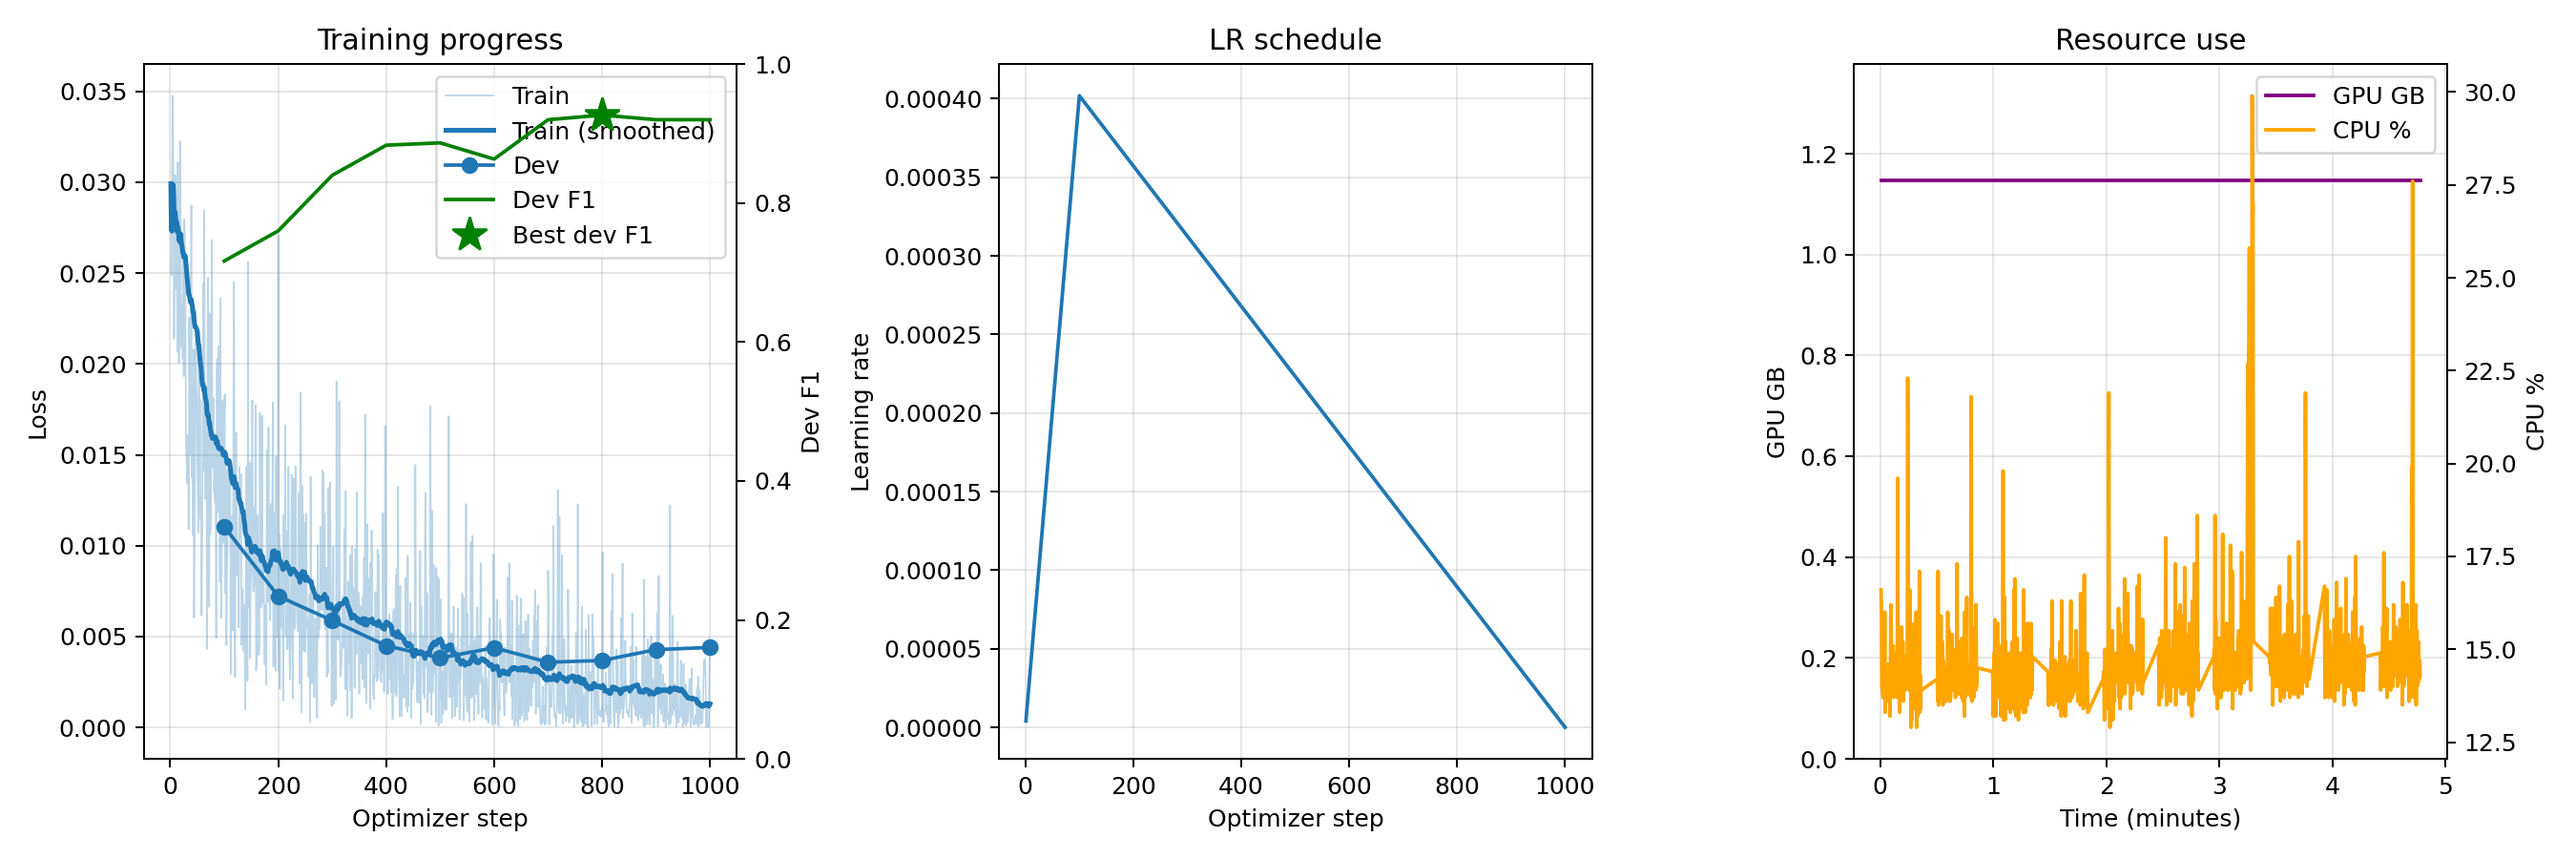

In [9]:
display(Image(filename=str(run / "plots" / "training_curves.png")))

## 7. Use the trained model

`predict` loads the adapter and runs on a GPU or a CPU:

```bash
active-gliner predict --adapter demo/run/adapter/best --task decision --labels "..." \
  --texts new.jsonl
```

In [10]:
new = [
    "how much money is in my checking account",
    "set a timer for ten minutes",
    "what is the meaning of life",
]
(demo / "new.jsonl").write_text("".join(json.dumps({"text": t}) + "\n" for t in new))
predictions = byod.predict(run / "adapter" / "best", TASK, labels, demo / "new.jsonl")
for text, prediction in zip(new, predictions, strict=True):
    print(text)
    print("   ", prediction["labels"])

how much money is in my checking account
    ['balance']
set a timer for ten minutes
    ['timer']
what is the meaning of life
    ['meaning of life']


## What the paper found for this task

Decisions tolerate LLM labels best: half LLM labels cost under one point. But on CLINC150 the LLM itself stays ahead of the small student, mostly on out-of-scope requests, so check that the student is good enough for your use.

See the paper (`paper/main.pdf`, Section 4.4) for the numbers on every dataset.